# VC · Práctica 5 — Transfer Learning en PyTorch: ResNet-18 vs. EfficientNet-B0 (FER-2013)

Entrenamiento mediante *transfer learning* (en dos fases: *warm-up* de la cabeza + *fine-tuning* completo) y comparativa directa entre **ResNet-18** y **EfficientNet-B0** sobre la misma partición estratificada (`SEED = 42`) usada en `VC_P5_CNN_entrenamiento_pytorch.ipynb`.

## 1. Configuración, semilla y librerías

In [1]:
import os, time, json, copy, random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from tqdm.auto import tqdm

SEED = 42

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    # warn_only=True evita errores en operaciones de interpolación/pooling en modelos preentrenados
    torch.use_deterministic_algorithms(True, warn_only=True)

set_seed(SEED)
print(f"Training seed: {SEED}")

Training seed: 42


In [2]:
# =====================  PARÁMETROS  =====================
DATA_DIR = Path(r"/home/cris/Proyectos/computer-vision/image-dataset/prac5_dataset")
TRAIN_DIR = DATA_DIR / "train"

IMG_SIZE = 48
TL_IMG_SIZE = 112        # Reescalado interno para backbones ImageNet (96 o 112 funciona muy bien en FER)
VAL_SIZE = 0.20

# Augmentation facial
AUG_ROTATION_DEG = 10.8
AUG_ZOOM = 0.10

# Entrenamiento en 2 fases
BATCH = 64
WARMUP_EPOCHS = 5        # Fase 1: solo cabeza clasificadora (backbone congelado)
FINETUNE_EPOCHS = 35     # Fase 2: fine-tuning completo
WARMUP_LR = 1e-3
FINETUNE_LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
ES_PATIENCE = 10         # Paciencia sobre val_loss en Fase 2

OUT_DIR = Path("outputs_p5")
MODELS_BASE_DIR = OUT_DIR / "models"
MODELS_BASE_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert TRAIN_DIR.is_dir(), f"No encuentro train/ en {DATA_DIR}"
print(
    f"PyTorch {torch.__version__} | device: {device}"
    + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
)

PyTorch 2.15.0+cu132 | device: cuda (NVIDIA GeForce RTX 3060 Ti)


## 2. Carga de datos y partición estratificada (80/20)

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def read_gray(path: Path):
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if img is not None and img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img

CLASS_NAMES = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
N_CLASSES = len(CLASS_NAMES)

X_full, y_full = [], []
for idx, cname in enumerate(CLASS_NAMES):
    files = sorted(f for f in (TRAIN_DIR / cname).iterdir() if f.suffix.lower() in IMG_EXT)
    for f in tqdm(files, desc=cname, leave=False):
        img = read_gray(f)
        if img is not None:
            X_full.append(img)
            y_full.append(idx)

X_full = np.stack(X_full).astype(np.uint8)
y_full = np.array(y_full, dtype=np.int64)
print("Clases:", CLASS_NAMES, "| train completo:", X_full.shape)

idx_tr, idx_val = train_test_split(
    np.arange(len(y_full)), test_size=VAL_SIZE, stratify=y_full, random_state=SEED
)
X_tr, y_tr = X_full[idx_tr], y_full[idx_tr]
X_val, y_val = X_full[idx_val], y_full[idx_val]

# Pesos suavizados (mismo criterio que en CNNFer)
cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
cw = cw ** 0.5
cw = cw / cw.mean()
cw_tensor = torch.tensor(cw, dtype=torch.float32)

print(f"train: {len(y_tr)} | val: {len(y_val)}")
print(pd.DataFrame({
    "train": np.bincount(y_tr, minlength=N_CLASSES),
    "val": np.bincount(y_val, minlength=N_CLASSES),
    "class_weight": np.round(cw, 2),
}, index=CLASS_NAMES))

def make_loader(X_arr, y_arr, batch_size=BATCH, shuffle=False):
    x_t = torch.from_numpy(X_arr[:, None, :, :])  # (N, 1, 48, 48) uint8
    y_t = torch.from_numpy(y_arr).long()
    ds = TensorDataset(x_t, y_t)
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=gen,
        pin_memory=(device.type == "cuda"),
    )

train_loader = make_loader(X_tr, y_tr, batch_size=BATCH, shuffle=True)
val_loader = make_loader(X_val, y_val, batch_size=256, shuffle=False)

angry:   0%|          | 0/3995 [00:00<?, ?it/s]

disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

happy:   0%|          | 0/7215 [00:00<?, ?it/s]

neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

sad:   0%|          | 0/4830 [00:00<?, ?it/s]

surprised:   0%|          | 0/3171 [00:00<?, ?it/s]

Clases: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised'] | train completo: (28709, 48, 48)
train: 22967 | val: 5742
           train   val  class_weight
angry       3196   799          0.81
disgusted    349    87          2.44
fearful     3277   820          0.80
happy       5772  1443          0.60
neutral     3972   993          0.72
sad         3864   966          0.73
surprised   2537   634          0.90


## 3. Wrapper de Transfer Learning (`TransferFER`)

Mantiene la entrada idéntica al resto de cuadernos `(B, 1, 48, 48)` `uint8` (`0-255`), aplica *data augmentation* en entrenamiento, reescala a `112×112`, replica a 3 canales y normaliza con las estadísticas de ImageNet.

In [4]:
class TransferFER(nn.Module):
    def __init__(
        self,
        backbone_name: str,
        n_classes: int = N_CLASSES,
        tl_img_size: int = TL_IMG_SIZE,
        aug_rotation_deg: float = AUG_ROTATION_DEG,
        aug_zoom: float = AUG_ZOOM,
        head_dropout: float = 0.30,
        pretrained: bool = True,
    ):
        super().__init__()
        self.backbone_name = backbone_name
        self.tl_img_size = tl_img_size

        self.augment = nn.Sequential(
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomAffine(
                degrees=aug_rotation_deg,
                translate=(0.08, 0.08),
                scale=(1.0 - aug_zoom, 1.0 + aug_zoom),
            ),
            v2.ColorJitter(brightness=0.2, contrast=0.2),
            v2.RandomErasing(p=0.25, scale=(0.02, 0.12)),
        )

        self.register_buffer(
            "imagenet_mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "imagenet_std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

        if backbone_name == "resnet18":
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            net = models.resnet18(weights=weights)
            in_feats = net.fc.in_features
            net.fc = nn.Sequential(
                nn.Dropout(p=head_dropout),
                nn.Linear(in_feats, n_classes),
            )
            self.head_module = net.fc
        elif backbone_name == "efficientnet_b0":
            weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
            net = models.efficientnet_b0(weights=weights)
            in_feats = net.classifier[1].in_features
            net.classifier = nn.Sequential(
                nn.Dropout(p=head_dropout),
                nn.Linear(in_feats, n_classes),
            )
            self.head_module = net.classifier
        else:
            raise ValueError(f"Backbone no soportado: {backbone_name}")

        self.backbone = net

    def set_backbone_trainable(self, trainable: bool):
        for p in self.backbone.parameters():
            p.requires_grad = trainable
        for p in self.head_module.parameters():
            p.requires_grad = True

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim == 4 and x.shape[-1] == 1 and x.shape[1] != 1:
            x = x.permute(0, 3, 1, 2)
        x = x.to(dtype=torch.float32) / 255.0
        if self.training:
            x = self.augment(x)
        if x.shape[-1] != self.tl_img_size or x.shape[-2] != self.tl_img_size:
            x = F.interpolate(
                x, size=(self.tl_img_size, self.tl_img_size), mode="bilinear", align_corners=False
            )
        x = x.repeat(1, 3, 1, 1)
        x = (x - self.imagenet_mean) / self.imagenet_std
        return self.backbone(x)

## 4. Funciones de entrenamiento (2 fases) y evaluación (con y sin TTA)

- **Fase 1:** 5 épocas entrenando solo la cabeza (`backbone` congelado).
- **Fase 2:** 35 épocas de *fine-tuning* completo con `CosineAnnealingLR`, guardando `best_weights` según `val_accuracy` y deteniendo por `EarlyStopping` si `val_loss` no mejora en `10` épocas.

In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    loss_sum, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if is_train:
                loss.backward()
                optimizer.step()

            bs = yb.size(0)
            loss_sum += loss.item() * bs
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += bs

    return loss_sum / total, correct / total


def train_transfer_model(backbone_name: str):
    set_seed(SEED)
    # Recrear train_loader con semilla reiniciada para igualdad exacta entre modelos
    tr_loader = make_loader(X_tr, y_tr, batch_size=BATCH, shuffle=True)

    model = TransferFER(backbone_name=backbone_name, pretrained=True).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    criterion = nn.CrossEntropyLoss(
        weight=cw_tensor.to(device), label_smoothing=LABEL_SMOOTHING
    )

    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": [], "lr": [], "phase": []}
    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_ep = 0
    best_weights = copy.deepcopy(model.state_dict())

    print(f"\n==================== {backbone_name.upper()} ({n_params:,} params) ====================")
    t0 = time.time()

    # --- Fase 1: Warm-up de la cabeza ---
    model.set_backbone_trainable(False)
    opt_warm = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=WARMUP_LR, weight_decay=WEIGHT_DECAY
    )
    for ep in range(1, WARMUP_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, tr_loader, criterion, opt_warm)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        history["loss"].append(tr_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(tr_acc)
        history["val_accuracy"].append(val_acc)
        history["lr"].append(WARMUP_LR)
        history["phase"].append("warmup")
        print(f"[Warmup {ep:02d}/{WARMUP_EPOCHS}] loss: {tr_loss:.4f} - acc: {tr_acc:.4f} | val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            best_ep = len(history["loss"]) - 1

    # --- Fase 2: Fine-tuning completo ---
    model.set_backbone_trainable(True)
    opt_ft = torch.optim.AdamW(model.parameters(), lr=FINETUNE_LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_ft, T_max=FINETUNE_EPOCHS, eta_min=1e-6
    )
    epochs_no_improve = 0

    for ep in range(1, FINETUNE_EPOCHS + 1):
        ep_t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, tr_loader, criterion, opt_ft)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        cur_lr = opt_ft.param_groups[0]["lr"]
        scheduler.step()

        history["loss"].append(tr_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(tr_acc)
        history["val_accuracy"].append(val_acc)
        history["lr"].append(cur_lr)
        history["phase"].append("finetune")

        ep_idx = len(history["loss"]) - 1
        print(
            f"[FT {ep:02d}/{FINETUNE_EPOCHS}] {time.time() - ep_t0:.1f}s - "
            f"loss: {tr_loss:.4f} - acc: {tr_acc:.4f} | "
            f"val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f} - lr: {cur_lr:.6f}"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            best_ep = ep_idx

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= ES_PATIENCE:
                print(f"Early stopping en época FT {ep}. Restaurando mejor val_acc de época global {best_ep + 1}.")
                break

    model.load_state_dict(best_weights)
    train_minutes = (time.time() - t0) / 60
    print(f"Finalizado {backbone_name} en {train_minutes:.1f} min | Mejor época global: {best_ep + 1} (val_acc={best_val_acc:.4f})")
    return model, history, best_ep, train_minutes


@torch.no_grad()
def predict_probs(net: nn.Module, X_arr: np.ndarray, batch_size: int = 256, use_tta: bool = True):
    net.eval()
    probs_list = []
    t0 = time.perf_counter()
    for i in range(0, len(X_arr), batch_size):
        xb = torch.from_numpy(X_arr[i:i + batch_size, None, :, :]).to(device)
        probs = F.softmax(net(xb), dim=-1)
        if use_tta:
            probs_flip = F.softmax(net(torch.flip(xb, dims=[-1])), dim=-1)
            probs = 0.5 * (probs + probs_flip)
        probs_list.append(probs.cpu().numpy())
    ms_per_img = ((time.perf_counter() - t0) / len(X_arr)) * 1000.0
    return np.concatenate(probs_list, axis=0), ms_per_img

## 5. Entrenamiento de ResNet-18 y EfficientNet-B0

In [7]:
resultados_tl = {}
for bname in ["resnet18", "efficientnet_b0"]:
    net, hist, best_ep, tr_min = train_transfer_model(bname)
    resultados_tl[bname] = {
        "model": net,
        "history": hist,
        "best_ep": best_ep,
        "train_minutes": tr_min,
        "params": sum(p.numel() for p in net.parameters()),
    }


==================== RESNET18 (11,180,103 params) ====================
[Warmup 01/5] loss: 1.9724 - acc: 0.2834 | val_loss: 1.8726 - val_acc: 0.3497
[Warmup 02/5] loss: 1.8999 - acc: 0.3221 | val_loss: 1.8416 - val_acc: 0.3765
[Warmup 03/5] loss: 1.8781 - acc: 0.3341 | val_loss: 1.8744 - val_acc: 0.3690
[Warmup 04/5] loss: 1.8799 - acc: 0.3328 | val_loss: 1.8850 - val_acc: 0.3473
[Warmup 05/5] loss: 1.8785 - acc: 0.3310 | val_loss: 1.9067 - val_acc: 0.3502
[FT 01/35] 13.5s - loss: 1.5951 - acc: 0.5013 | val_loss: 1.4735 - val_acc: 0.5472 - lr: 0.000300
[FT 02/35] 13.0s - loss: 1.4393 - acc: 0.5757 | val_loss: 1.4014 - val_acc: 0.5982 - lr: 0.000299
[FT 03/35] 13.3s - loss: 1.3773 - acc: 0.6077 | val_loss: 1.4052 - val_acc: 0.5942 - lr: 0.000298
[FT 04/35] 13.2s - loss: 1.3488 - acc: 0.6252 | val_loss: 1.3259 - val_acc: 0.6388 - lr: 0.000295
[FT 05/35] 12.7s - loss: 1.3091 - acc: 0.6411 | val_loss: 1.3753 - val_acc: 0.6148 - lr: 0.000290
[FT 06/35] 12.7s - loss: 1.2824 - acc: 0.6537 | 

100%|██████████| 20.5M/20.5M [00:01<00:00, 10.9MB/s]



==================== EFFICIENTNET_B0 (4,016,515 params) ====================
[Warmup 01/5] loss: 1.8947 - acc: 0.3111 | val_loss: 1.8501 - val_acc: 0.3527
[Warmup 02/5] loss: 1.8506 - acc: 0.3442 | val_loss: 1.8234 - val_acc: 0.3751
[Warmup 03/5] loss: 1.8441 - acc: 0.3492 | val_loss: 1.8529 - val_acc: 0.3636
[Warmup 04/5] loss: 1.8467 - acc: 0.3444 | val_loss: 1.8439 - val_acc: 0.3664
[Warmup 05/5] loss: 1.8501 - acc: 0.3448 | val_loss: 1.8234 - val_acc: 0.3732
[FT 01/35] 23.5s - loss: 1.6349 - acc: 0.4766 | val_loss: 1.4692 - val_acc: 0.5540 - lr: 0.000300
[FT 02/35] 23.1s - loss: 1.4579 - acc: 0.5685 | val_loss: 1.3805 - val_acc: 0.5980 - lr: 0.000299
[FT 03/35] 23.1s - loss: 1.3784 - acc: 0.6047 | val_loss: 1.3446 - val_acc: 0.6231 - lr: 0.000298
[FT 04/35] 23.2s - loss: 1.3228 - acc: 0.6343 | val_loss: 1.3230 - val_acc: 0.6296 - lr: 0.000295
[FT 05/35] 23.2s - loss: 1.2755 - acc: 0.6544 | val_loss: 1.3186 - val_acc: 0.6404 - lr: 0.000290
[FT 06/35] 23.2s - loss: 1.2411 - acc: 0.6

## 6. Curvas de entrenamiento, evaluación en validación y matrices de confusión

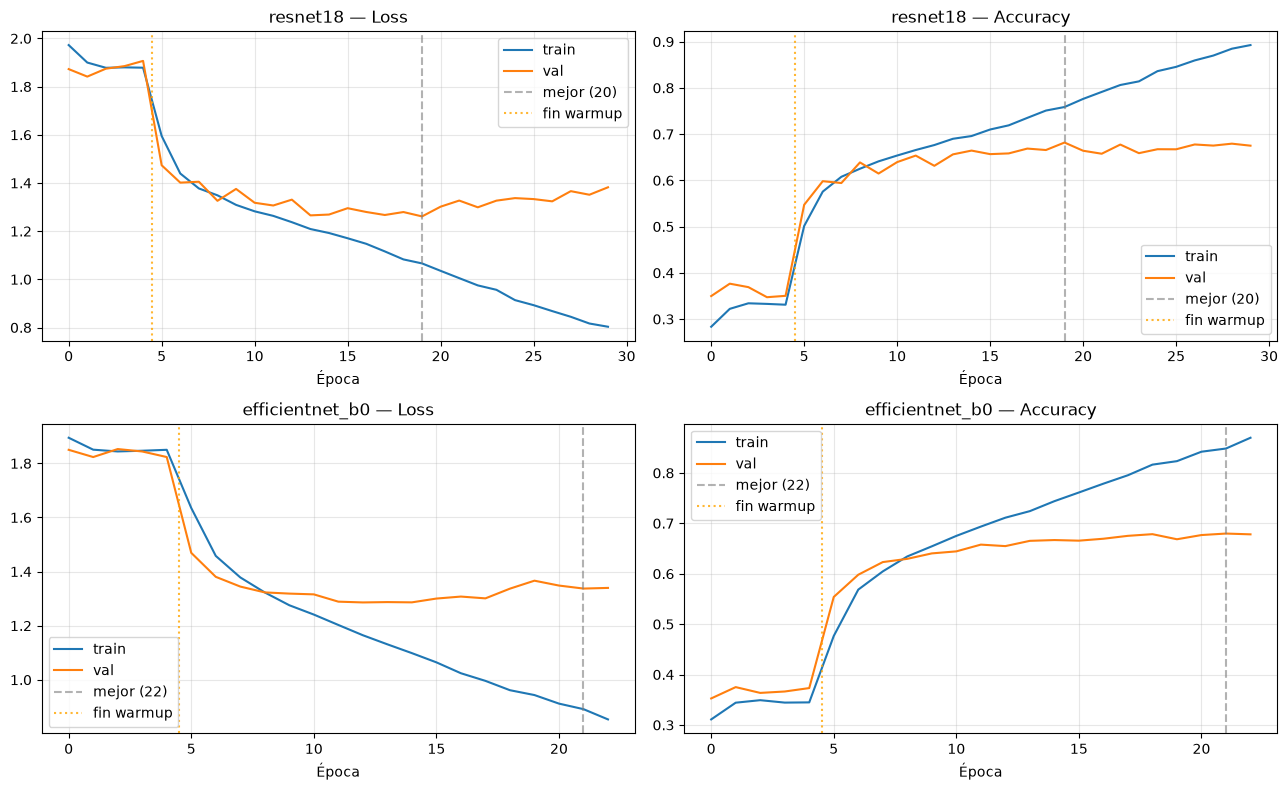

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (bname, info) in enumerate(resultados_tl.items()):
    h = info["history"]
    best_ep = info["best_ep"]
    axes[row, 0].plot(h["loss"], label="train")
    axes[row, 0].plot(h["val_loss"], label="val")
    axes[row, 0].axvline(best_ep, color="gray", ls="--", alpha=0.6, label=f"mejor ({best_ep + 1})")
    axes[row, 0].axvline(WARMUP_EPOCHS - 0.5, color="orange", ls=":", alpha=0.8, label="fin warmup")
    axes[row, 0].set_title(f"{bname} — Loss")
    axes[row, 0].set_xlabel("Época")
    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(h["accuracy"], label="train")
    axes[row, 1].plot(h["val_accuracy"], label="val")
    axes[row, 1].axvline(best_ep, color="gray", ls="--", alpha=0.6, label=f"mejor ({best_ep + 1})")
    axes[row, 1].axvline(WARMUP_EPOCHS - 0.5, color="orange", ls=":", alpha=0.8, label="fin warmup")
    axes[row, 1].set_title(f"{bname} — Accuracy")
    axes[row, 1].set_xlabel("Época")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


=== RESNET18 (con TTA) -> accuracy=0.6877 | F1-macro=0.6693 ===
              precision    recall  f1-score   support

       angry       0.59      0.60      0.60       799
   disgusted       0.64      0.68      0.66        87
     fearful       0.58      0.55      0.56       820
       happy       0.84      0.89      0.87      1443
     neutral       0.63      0.65      0.64       993
         sad       0.60      0.55      0.57       966
   surprised       0.79      0.78      0.78       634

    accuracy                           0.69      5742
   macro avg       0.67      0.67      0.67      5742
weighted avg       0.68      0.69      0.69      5742


=== EFFICIENTNET_B0 (con TTA) -> accuracy=0.6829 | F1-macro=0.6624 ===
              precision    recall  f1-score   support

       angry       0.61      0.58      0.59       799
   disgusted       0.56      0.71      0.63        87
     fearful       0.54      0.59      0.56       820
       happy       0.87      0.88      0.87      

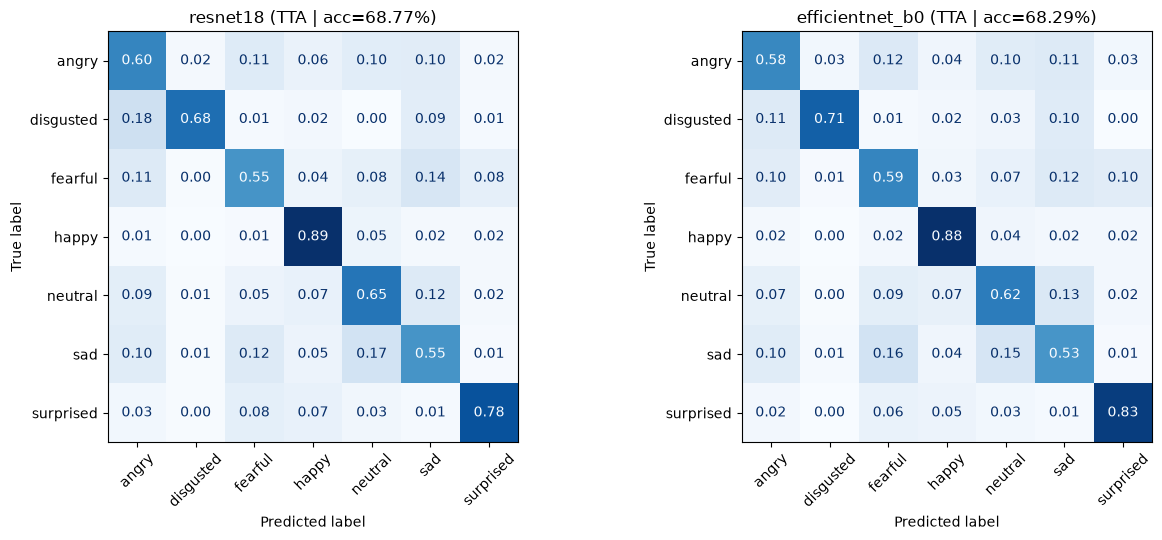

,modelo,params_M,train_min,mejor_epoca,val_acc_sin_tta_pct,val_f1_sin_tta_pct,val_acc_con_tta_pct,val_f1_con_tta_pct,ms_por_img_tta
0,resnet18,11.18,5.9,20,68.18,66.41,68.77,66.93,0.253
1,efficientnet_b0,4.02,7.5,22,67.97,66.01,68.29,66.24,0.406


In [9]:
filas_comparativa = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, (bname, info) in zip(axes, resultados_tl.items()):
    net = info["model"]
    p_no_tta, ms_no_tta = predict_probs(net, X_val, use_tta=False)
    p_tta, ms_tta = predict_probs(net, X_val, use_tta=True)

    y_pred_no_tta = p_no_tta.argmax(1)
    y_pred_tta = p_tta.argmax(1)

    acc_no_tta = float(np.mean(y_pred_no_tta == y_val))
    f1_no_tta = float(f1_score(y_val, y_pred_no_tta, average="macro"))
    acc_tta = float(np.mean(y_pred_tta == y_val))
    f1_tta = float(f1_score(y_val, y_pred_tta, average="macro"))

    info["val_acc_no_tta"] = acc_no_tta
    info["val_f1_no_tta"] = f1_no_tta
    info["val_acc_tta"] = acc_tta
    info["val_f1_tta"] = f1_tta
    info["ms_img_tta"] = ms_tta
    info["p_val_tta"] = p_tta

    filas_comparativa.append({
        "modelo": bname,
        "params_M": round(info["params"] / 1e6, 2),
        "train_min": round(info["train_minutes"], 1),
        "mejor_epoca": info["best_ep"] + 1,
        "val_acc_sin_tta_pct": round(acc_no_tta * 100, 2),
        "val_f1_sin_tta_pct": round(f1_no_tta * 100, 2),
        "val_acc_con_tta_pct": round(acc_tta * 100, 2),
        "val_f1_con_tta_pct": round(f1_tta * 100, 2),
        "ms_por_img_tta": round(ms_tta, 3),
    })

    print(f"\n=== {bname.upper()} (con TTA) -> accuracy={acc_tta:.4f} | F1-macro={f1_tta:.4f} ===")
    print(classification_report(y_val, y_pred_tta, target_names=CLASS_NAMES, zero_division=0))

    cm = confusion_matrix(y_val, y_pred_tta, labels=range(N_CLASSES), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f"
    )
    ax.set_title(f"{bname} (TTA | acc={acc_tta:.2%})")

plt.tight_layout()
plt.show()

df_comp = pd.DataFrame(filas_comparativa)
display(df_comp)

## 7. Comparativa visual directa y guardado de ambos modelos

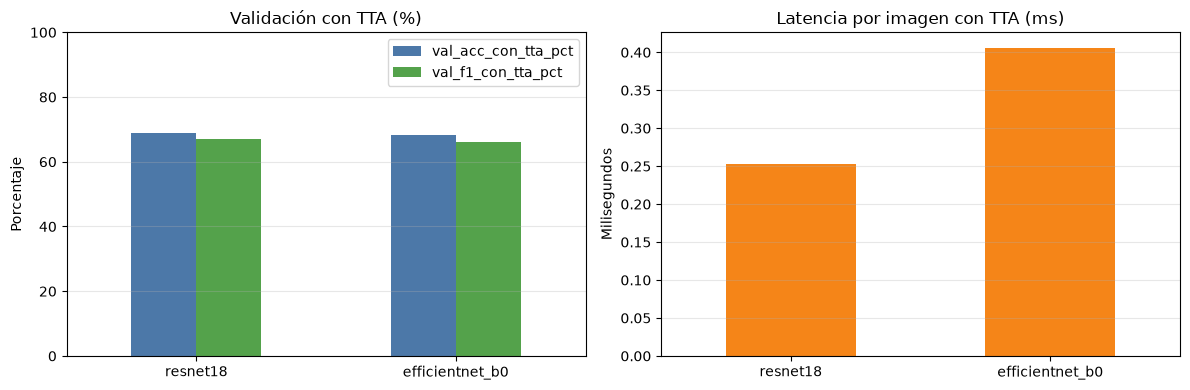

Modelo recomendado para la comparativa final: resnet18 (Val Acc=68.77 %, F1-macro=66.93 %)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_comp.plot.bar(
    x="modelo", y=["val_acc_con_tta_pct", "val_f1_con_tta_pct"], ax=axes[0],
    color=["#4c78a8", "#54a24b"], title="Validación con TTA (%)"
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Porcentaje")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

df_comp.plot.bar(
    x="modelo", y="ms_por_img_tta", ax=axes[1], legend=False,
    color="#f58518", title="Latencia por imagen con TTA (ms)"
)
axes[1].set_xlabel("")
axes[1].set_ylabel("Milisegundos")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

ganador = df_comp.sort_values(
    ["val_f1_con_tta_pct", "val_acc_con_tta_pct"], ascending=False
).iloc[0]
print(
    f"Modelo recomendado para la comparativa final: {ganador['modelo']} "
    f"(Val Acc={ganador['val_acc_con_tta_pct']} %, F1-macro={ganador['val_f1_con_tta_pct']} %)"
)

In [11]:
# Guardar ambos checkpoints y configuraciones para usarlos en la comparativa final
for bname, info in resultados_tl.items():
    mdir = MODELS_BASE_DIR / f"v1_TL_{bname}"
    mdir.mkdir(parents=True, exist_ok=True)
    mname = f"{bname}_fer_torch_seed{SEED}"
    mpath = mdir / f"{mname}.pt"

    checkpoint = {
        "model_state_dict": info["model"].state_dict(),
        "class_names": CLASS_NAMES,
        "arch": {
            "backbone_name": bname,
            "n_classes": N_CLASSES,
            "tl_img_size": TL_IMG_SIZE,
            "aug_rotation_deg": AUG_ROTATION_DEG,
            "aug_zoom": AUG_ZOOM,
            "head_dropout": 0.30,
            "pretrained": False,  # Al recargar no hace falta descargar pesos de ImageNet
        },
    }
    torch.save(checkpoint, mpath)
    json.dump(CLASS_NAMES, open(mdir / "class_names.json", "w"))
    pd.DataFrame(info["history"]).to_csv(mdir / f"{mname}_history.csv", index=False)

    cfg = {
        "framework": "pytorch",
        "backbone": bname,
        "seed": SEED,
        "tl_img_size": TL_IMG_SIZE,
        "warmup_epochs": WARMUP_EPOCHS,
        "finetune_epochs": FINETUNE_EPOCHS,
        "epochs_run": len(info["history"]["loss"]),
        "best_epoch": info["best_ep"] + 1,
        "val_acc_no_tta": info["val_acc_no_tta"],
        "val_f1_no_tta": info["val_f1_no_tta"],
        "val_acc_tta": info["val_acc_tta"],
        "val_f1_tta": info["val_f1_tta"],
        "train_minutes": round(info["train_minutes"], 1),
    }
    json.dump(cfg, open(mdir / f"{mname}_config.json", "w"), indent=2)

    # Comprobación de recarga exacta
    ckpt = torch.load(mpath, map_location=device, weights_only=True)
    reloaded = TransferFER(**ckpt["arch"]).to(device)
    reloaded.load_state_dict(ckpt["model_state_dict"])
    p_orig, _ = predict_probs(info["model"], X_val[:64], use_tta=True)
    p_rel, _ = predict_probs(reloaded, X_val[:64], use_tta=True)
    same = np.allclose(p_rel, p_orig, atol=1e-5)
    print(f"Guardado {mpath.resolve()} | recarga OK: {same}")

Guardado /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_TL_resnet18/resnet18_fer_torch_seed42.pt | recarga OK: True
Guardado /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_TL_efficientnet_b0/efficientnet_b0_fer_torch_seed42.pt | recarga OK: True
